# 07 - RAG com LangGraph

Caso prático: um **assistente de atendimento** que responde perguntas sobre as políticas de uma loja fictícia. Em vez de depender do que o LLM "lembra", o grafo busca trechos de documentos e responde com base neles.

Fluxo:

```
START → recuperar → avaliar ──(relevante)────────────→ gerar → END
                       │
                       ├──(irrelevante, ainda pode tentar)──→ reescrever → recuperar
                       └──(irrelevante, sem tentativas)─────→ sem_resposta → END
```

- **Indexação**: os documentos são divididos em trechos, convertidos em vetores (embeddings) e guardados num vector store.
- **Recuperação**: a pergunta vira um vetor, e os trechos mais parecidos são retornados.
- **Avaliação**: um LLM confere se os trechos realmente respondem à pergunta. Isso evita responder com contexto ruim.
- **Reescrita**: se a busca falhou, o LLM reescreve a pergunta para uma nova busca. O número de tentativas é limitado.
- **Geração**: o LLM responde usando só os trechos recuperados.

## 1. Configuração

A chave e o modelo vêm do `.env` na raiz do projeto, como nos outros notebooks. Os embeddings usam `text-embedding-3-small`, da própria OpenAI.

In [1]:
import math
import os
from typing import TypedDict

from dotenv import find_dotenv, load_dotenv
from IPython.display import Markdown, display
from langchain_core.documents import Document
from langchain_core.messages import HumanMessage, SystemMessage
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langgraph.graph import END, START, StateGraph
from pydantic import BaseModel, Field

from IPython.display import Markdown, display
from IPython.display import Image

load_dotenv(find_dotenv())

API_KEY = os.getenv("OPENAI_API_KEY")

llm = ChatOpenAI(model=os.getenv("OPENAI_MODEL", "gpt-5-mini"), api_key=API_KEY)
embeddings = OpenAIEmbeddings(model="text-embedding-3-small", api_key=API_KEY)

## 2. Documentos da loja

Os textos são fictícios e representam uma base de conhecimento real: políticas que um atendente consultaria. Cada documento tem um `source`, usado para citar a origem da resposta.

In [2]:
DOCUMENTOS = {
    "politica-devolucoes.md": """
Prazo de devolução: o cliente pode devolver um produto em até 7 dias corridos após o recebimento.
O produto deve estar sem uso, na embalagem original e com todos os acessórios.

Reembolso: o valor é devolvido em até 10 dias úteis. Para cartão de crédito, o estorno aparece na fatura seguinte.
Para Pix, o reembolso cai na conta indicada pelo cliente.

Frete na devolução: se o motivo for arrependimento, o frete de devolução é pago pelo cliente.
Se o produto chegou com defeito ou errado, a loja paga o frete.
""",
    "politica-trocas-garantia.md": """
Trocas: a troca por outro tamanho ou cor é feita em até 30 dias, desde que haja estoque.
Produtos personalizados, como gravações ou tamanhos sob medida, não podem ser trocados, exceto em caso de defeito.

Garantia: todos os produtos eletrônicos têm garantia de 12 meses contra defeitos de fabricação.
Para acionar a garantia, o cliente deve apresentar a nota fiscal e o número de série.
""",
    "politica-entregas.md": """
Prazo de entrega: capitais recebem em 3 a 5 dias úteis. Demais cidades, em 5 a 10 dias úteis.
O rastreio é enviado por e-mail assim que o pedido é despachado.

Retirada na loja: o pedido fica disponível por 48 horas após a confirmação de que está pronto.
""",
}

## 3. Indexação

A função `dividir` separa cada documento em trechos, usando linhas em branco como fronteira. Cada trecho vira um `Document` com o nome do arquivo nos metadados. Depois, `indice.adicionar` gera os embeddings e guarda os vetores.

Em documentos longos, convém usar um divisor com sobreposição entre trechos (por exemplo, `RecursiveCharacterTextSplitter`). Aqui os textos já são curtos, então a divisão por parágrafos basta.

In [3]:
def dividir(nome: str, texto: str) -> list[Document]:
    trechos = [t.strip() for t in texto.split("\n\n") if t.strip()]
    return [Document(page_content=t, metadata={"source": nome}) for t in trechos]


chunks = [doc for nome, texto in DOCUMENTOS.items() for doc in dividir(nome, texto)]


class IndiceVetorial:
    """Índice em memória: guarda (vetor, documento) e busca pela similaridade do cosseno."""

    def __init__(self, embeddings):
        self.embeddings = embeddings
        self.itens = []

    def adicionar(self, documentos: list[Document]) -> None:
        vetores = self.embeddings.embed_documents([d.page_content for d in documentos])
        self.itens.extend(zip(vetores, documentos))

    def buscar(self, consulta: str, k: int = 3) -> list[Document]:
        q = self.embeddings.embed_query(consulta)
        normq = math.sqrt(sum(x * x for x in q))

        def similaridade(v):
            normv = math.sqrt(sum(x * x for x in v))
            return sum(a * b for a, b in zip(q, v)) / (normq * normv)

        ordenados = sorted(self.itens, key=lambda item: similaridade(item[0]), reverse=True)
        return [doc for _, doc in ordenados[:k]]


indice = IndiceVetorial(embeddings)
indice.adicionar(chunks)

print(f"{len(chunks)} trechos indexados.")

7 trechos indexados.


## 4. Estado e modelo de avaliação

O estado guarda a pergunta, os trechos recuperados, o resultado da avaliação, a resposta e o número de tentativas.

`Avaliacao` é o formato da resposta do LLM na etapa de avaliação. `with_structured_output` garante que a resposta seja um `bool`, sem precisar interpretar texto.

In [4]:
class Estado(TypedDict):
    pergunta: str
    documentos: list[Document]
    relevante: bool
    resposta: str
    tentativas: int


class Avaliacao(BaseModel):
    relevante: bool = Field(description="True se os trechos contêm a informação necessária para responder à pergunta.")


llm_avaliador = llm.with_structured_output(Avaliacao)

MAX_TENTATIVAS = 2

## 5. Nós

- `recuperar` busca os 3 trechos mais parecidos com a pergunta atual.
- `avaliar` confere se esses trechos respondem à pergunta.
- `reescrever` cria uma pergunta de busca mais específica. Ela é usada na próxima recuperação.
- `gerar` responde usando só os trechos e cita a origem.
- `sem_resposta` devolve uma mensagem honesta quando nada útil foi encontrado.

In [5]:
def recuperar(estado: Estado) -> dict:
    documentos = indice.buscar(estado["pergunta"], k=3)
    return {"documentos": documentos, "tentativas": estado["tentativas"] + 1}


def avaliar(estado: Estado) -> dict:
    trechos = "\n\n".join(f"[{d.metadata['source']}] {d.page_content}" for d in estado["documentos"])
    avaliacao = llm_avaliador.invoke([
        SystemMessage(content="Você confere se os trechos respondem à pergunta. Seja rigoroso: trechos parecidos mas sem a resposta não contam."),
        HumanMessage(content=f"Pergunta: {estado['pergunta']}\n\nTrechos:\n{trechos}"),
    ])
    return {"relevante": avaliacao.relevante}


def reescrever(estado: Estado) -> dict:
    nova = llm.invoke([
        SystemMessage(content="Reescreva a pergunta como uma consulta curta e específica para buscar em documentos de políticas de loja. Responda apenas com a consulta, em português."),
        HumanMessage(content=estado["pergunta"]),
    ])
    return {"pergunta": nova.content}


def gerar(estado: Estado) -> dict:
    trechos = "\n\n".join(f"[{d.metadata['source']}] {d.page_content}" for d in estado["documentos"])
    resposta = llm.invoke([
        SystemMessage(content=(
            "Você é um atendente de loja. Responda em português usando somente os trechos fornecidos. "
            "Cite entre colchetes o arquivo de origem. Se a resposta não estiver nos trechos, diga que não sabe."
        )),
        HumanMessage(content=f"Pergunta: {estado['pergunta']}\n\nTrechos:\n{trechos}"),
    ])
    return {"resposta": resposta.content}


def sem_resposta(estado: Estado) -> dict:
    return {"resposta": "Não encontrei essa informação nas políticas da loja. Vou encaminhar sua pergunta a um atendente."}

## 6. Arestas condicionais e compilação

`apos_avaliacao` decide o caminho: relevante vai para `gerar`. Irrelevante volta para `reescrever`, a menos que o limite de tentativas tenha sido atingido.

In [6]:
def apos_avaliacao(estado: Estado) -> str:
    if estado["relevante"]:
        return "gerar"
    if estado["tentativas"] >= MAX_TENTATIVAS:
        return "sem_resposta"
    return "reescrever"


grafo = StateGraph(Estado)
grafo.add_node("recuperar", recuperar)
grafo.add_node("avaliar", avaliar)
grafo.add_node("reescrever", reescrever)
grafo.add_node("gerar", gerar)
grafo.add_node("sem_resposta", sem_resposta)

grafo.add_edge(START, "recuperar")
grafo.add_edge("recuperar", "avaliar")
grafo.add_conditional_edges("avaliar", apos_avaliacao, ["gerar", "reescrever", "sem_resposta"])
grafo.add_edge("reescrever", "recuperar")
grafo.add_edge("gerar", END)
grafo.add_edge("sem_resposta", END)

app = grafo.compile()

## 7. Visualizando o grafo

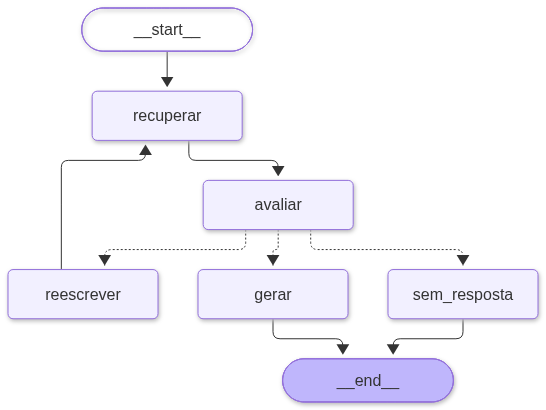

In [7]:
display(Image(app.get_graph().draw_mermaid_png()))

## 8. Executando

`perguntar` mostra a resposta, a origem dos trechos usados e quantas buscas foram feitas. As três perguntas cobrem: um caso coberto pelos documentos, outro com regra de exceção e um fora do escopo.

In [8]:
def perguntar(texto: str) -> None:
    estado = app.invoke({"pergunta": texto, "documentos": [], "relevante": False, "resposta": "", "tentativas": 0})

    origens = sorted({d.metadata["source"] for d in estado["documentos"]})
    linhas = [
        f"**Pergunta:** {texto}",
        "",
        f"**Buscas feitas:** {estado['tentativas']}",
        f"**Trechos usados:** {', '.join(origens) or 'nenhum'}",
        "",
        f"**Resposta:** {estado['resposta']}",
    ]
    display(Markdown("\n".join(linhas)))


perguntar("Qual é o prazo para devolver um produto?")

**Pergunta:** Qual é o prazo para devolver um produto?

**Buscas feitas:** 1
**Trechos usados:** politica-devolucoes.md, politica-trocas-garantia.md

**Resposta:** Prazo de devolução: o cliente pode devolver um produto em até 7 dias corridos após o recebimento. O produto deve estar sem uso, na embalagem original e com todos os acessórios. [politica-devolucoes.md]

In [9]:
perguntar("Posso trocar um produto personalizado com gravação?")

**Pergunta:** Posso trocar um produto personalizado com gravação?

**Buscas feitas:** 1
**Trechos usados:** politica-devolucoes.md, politica-trocas-garantia.md

**Resposta:** Produtos personalizados, como gravações ou tamanhos sob medida, não podem ser trocados, exceto em caso de defeito. [politica-trocas-garantia.md]

In [10]:
perguntar("Qual é a capital da França?")

**Pergunta:** Qual é a capital da França?

**Buscas feitas:** 2
**Trechos usados:** politica-devolucoes.md, politica-entregas.md

**Resposta:** Não encontrei essa informação nas políticas da loja. Vou encaminhar sua pergunta a um atendente.

## 9. Por que RAG e não só o LLM

- **Informação atual e privada**: o LLM não conhece as políticas da loja. Os documentos são a fonte.
- **Citação**: a resposta indica de onde veio, o que facilita conferir.
- **Recusa honesta**: a etapa de avaliação impede que o modelo invente uma regra quando a busca não encontra nada.
- **Reescrita limitada**: a reescrita melhora a busca, mas `MAX_TENTATIVAS` impede loops infinitos e chamadas desnecessárias.